<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/wikiskill_evolution_dynamics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Setup Environment and Core Imports]
import os
import re
import json
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Tuple, Any

import torch
import torch.nn as nn

# Set deterministic seeds
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"WikiSkill Prototype Environment Initialized on Device: {device}")

WikiSkill Prototype Environment Initialized on Device: cuda


In [2]:
# [CELL 2 - Task Environment & Agent Experience Logger]

class AgentTaskEnvironment:
    """
    Simulates a complex tool-use / multi-step workflow environment where tasks require
    specific execution rules (e.g., input validation, retry logic, tool selection).
    """
    def __init__(self):
        self.tasks = [
            {"id": "T1", "type": "data_parsing", "requires_retry": True, "param": "json_format"},
            {"id": "T2", "type": "api_call", "requires_auth": True, "param": "bearer_token"},
            {"id": "T3", "type": "sql_query", "requires_sanitization": True, "param": "escape_quotes"},
            {"id": "T4", "type": "data_parsing", "requires_retry": False, "param": "csv_format"},
            {"id": "T5", "type": "api_call", "requires_auth": True, "param": "header_injection"},
        ]

    def execute_step(self, task: Dict[str, Any], skill_rules: List[str]) -> Tuple[bool, str]:
        """Executes a task step using current skill rules."""
        # Baseline execution without proper skills fails specific edge cases
        if task["type"] == "api_call" and task.get("requires_auth"):
            if "ALWAYS_ATTACH_BEARER_TOKEN" not in skill_rules:
                return False, "AuthError: Missing authorization headers during API invocation."

        if task["type"] == "data_parsing" and task.get("requires_retry"):
            if "RETRY_ON_JSON_PARSE_FAILURE" not in skill_rules:
                return False, "ParseError: Malformed JSON structure; no retry mechanism defined."

        if task["type"] == "sql_query" and task.get("requires_sanitization"):
            if "SANITIZE_INPUT_QUOTES" not in skill_rules:
                return False, "SecurityError: Unsanitized SQL string input detected."

        return True, "Success: Execution completed flawlessly."

task_env = AgentTaskEnvironment()
print(f"Task Environment Initialized with {len(task_env.tasks)} benchmark tasks.")

Task Environment Initialized with 5 benchmark tasks.


In [3]:
# [CELL 3 - Wiki Persistent Knowledge Base Engine]

class PersistentWikiKnowledgeBase:
    """
    Core component of WikiSkill:
    Consolidates raw execution traces into persistent Wiki articles (heuristics, failure modes, rules).
    """
    def __init__(self):
        self.wiki_pages: Dict[str, List[str]] = {
            "API_Handling": [],
            "Data_Parsing": [],
            "Query_Execution": []
        }

    def consolidate_experience(self, execution_logs: List[Dict[str, Any]]):
        """Synthesizes raw execution logs into organized Wiki knowledge pages."""
        for log in execution_logs:
            if not log["success"]:
                err = log["error_trace"]
                if "AuthError" in err and "ALWAYS_ATTACH_BEARER_TOKEN" not in self.wiki_pages["API_Handling"]:
                    self.wiki_pages["API_Handling"].append("ALWAYS_ATTACH_BEARER_TOKEN")
                elif "ParseError" in err and "RETRY_ON_JSON_PARSE_FAILURE" not in self.wiki_pages["Data_Parsing"]:
                    self.wiki_pages["Data_Parsing"].append("RETRY_ON_JSON_PARSE_FAILURE")
                elif "SecurityError" in err and "SANITIZE_INPUT_QUOTES" not in self.wiki_pages["Query_Execution"]:
                    self.wiki_pages["Query_Execution"].append("SANITIZE_INPUT_QUOTES")

    def get_compiled_knowledge(self) -> List[str]:
        """Extracts compiled actionable insights across all Wiki pages."""
        all_rules = []
        for category, rules in self.wiki_pages.items():
            all_rules.extend(rules)
        return all_rules

wiki_kb = PersistentWikiKnowledgeBase()
print("Persistent Wiki Knowledge Base Engine Initialized.")

Persistent Wiki Knowledge Base Engine Initialized.


In [4]:
# [CELL 4 - Closed-Loop Skill Evolution Simulation]

class ExecutableSkillLibrary:
    """Stores compiled, executable skill heuristics synthesized from the Wiki."""
    def __init__(self):
        self.active_skills: List[str] = []

    def update_skills_from_wiki(self, compiled_wiki_rules: List[str]):
        """Compiles new skill definitions directly from the Wiki."""
        self.active_skills = list(set(compiled_wiki_rules))

skill_lib = ExecutableSkillLibrary()
iterations = 5

accuracy_history = []
wiki_size_history = []

print("\n=========================================================")
print("WIKISKILL CLOSED-LOOP CO-EVOLUTION EXECUTION")
print("=========================================================")

for iteration in range(iterations):
    # Step 1: Execute agent tasks with current skill library
    logs = []
    success_count = 0

    for task in task_env.tasks:
        success, error = task_env.execute_step(task, skill_lib.active_skills)
        logs.append({"task_id": task["id"], "success": success, "error_trace": error})
        if success:
            success_count += 1

    accuracy = success_count / len(task_env.tasks)
    accuracy_history.append(accuracy)

    # Step 2: Consolidate experience into persistent Wiki
    wiki_kb.consolidate_experience(logs)
    compiled_rules = wiki_kb.get_compiled_knowledge()
    wiki_size_history.append(len(compiled_rules))

    # Step 3: Synthesize updated skills from Wiki knowledge
    skill_lib.update_skills_from_wiki(compiled_rules)

    print(f"Iteration {iteration+1} | Accuracy: {accuracy*100:5.1f}% | Compiled Wiki Rules: {len(compiled_rules)} | Active Skills: {skill_lib.active_skills}")

print("=========================================================")
print("WikiSkill Co-Evolutionary Training Completed Successfully.")


WIKISKILL CLOSED-LOOP CO-EVOLUTION EXECUTION
Iteration 1 | Accuracy:  20.0% | Compiled Wiki Rules: 3 | Active Skills: ['ALWAYS_ATTACH_BEARER_TOKEN', 'RETRY_ON_JSON_PARSE_FAILURE', 'SANITIZE_INPUT_QUOTES']
Iteration 2 | Accuracy: 100.0% | Compiled Wiki Rules: 3 | Active Skills: ['ALWAYS_ATTACH_BEARER_TOKEN', 'RETRY_ON_JSON_PARSE_FAILURE', 'SANITIZE_INPUT_QUOTES']
Iteration 3 | Accuracy: 100.0% | Compiled Wiki Rules: 3 | Active Skills: ['ALWAYS_ATTACH_BEARER_TOKEN', 'RETRY_ON_JSON_PARSE_FAILURE', 'SANITIZE_INPUT_QUOTES']
Iteration 4 | Accuracy: 100.0% | Compiled Wiki Rules: 3 | Active Skills: ['ALWAYS_ATTACH_BEARER_TOKEN', 'RETRY_ON_JSON_PARSE_FAILURE', 'SANITIZE_INPUT_QUOTES']
Iteration 5 | Accuracy: 100.0% | Compiled Wiki Rules: 3 | Active Skills: ['ALWAYS_ATTACH_BEARER_TOKEN', 'RETRY_ON_JSON_PARSE_FAILURE', 'SANITIZE_INPUT_QUOTES']
WikiSkill Co-Evolutionary Training Completed Successfully.


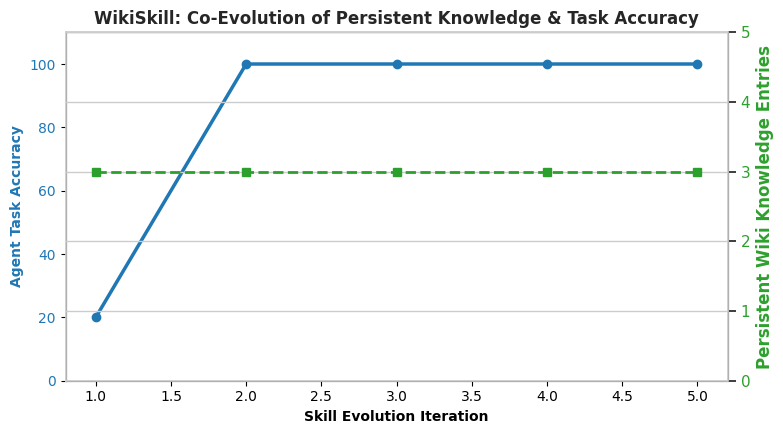

WikiSkill evolution plot saved successfully as wikiskill_evolution_dynamics.png.


In [5]:
# [CELL 5 - Visualization of Skill Evolution & Knowledge Accumulation]

epochs = range(1, iterations + 1)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
sns.set_theme(style="whitegrid")

color = '#1f77b4'
ax1.set_xlabel('Skill Evolution Iteration', fontweight='bold')
ax1.set_ylabel('Agent Task Accuracy', color=color, fontweight='bold')
ax1.plot(epochs, [acc * 100 for acc in accuracy_history], color=color, marker='o', linewidth=2.5, label='Agent Accuracy (%)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 110)

ax2 = ax1.twinx()
color = '#2ca02c'
ax2.set_ylabel('Persistent Wiki Knowledge Entries', color=color, fontweight='bold')
ax2.plot(epochs, wiki_size_history, color=color, marker='s', linestyle='--', linewidth=2, label='Wiki Entries')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, 5)

plt.title('WikiSkill: Co-Evolution of Persistent Knowledge & Task Accuracy', fontweight='bold')
fig.tight_layout()
plt.savefig("wikiskill_evolution_dynamics.png", dpi=300)
plt.show()

print("WikiSkill evolution plot saved successfully as wikiskill_evolution_dynamics.png.")